# Kathmandu AQI Prediction: Full Pipeline (v2)
**Module:** CSC61304 Machine Learning and Intelligent Systems | **Track:** ML for Air Quality Monitoring

**Goal:** predict `us_aqi` for Kathmandu from weather and time features.

**Pipeline order:** 1. Load data, 2. Data checks, 3. EDA, 4. Train/test split, 5. Feature engineering, 6. Feature selection, 7. Modeling, 8. Evaluation, 9. Save model.

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             confusion_matrix, ConfusionMatrixDisplay)

## 1. Load data
Hourly Kathmandu weather + air quality data from Open-Meteo.

In [2]:
df = pd.read_csv("kathmandu_final.csv")

In [3]:
# Show all columns when printing tables
pd.set_option("display.max_columns", None)

### 1.1 First look: rows, shape, columns, types

In [4]:
df.head()

,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,weather_code,pressure_msl,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi,hour,month,day_of_week,is_weekend
0,2022-08-05 05:00:00,20.3,98,20.0,23.6,4.2,4.2,63,1008.6,100,4.2,110,11.2,31.7,22.2,478.0,14.1,5.2,68.0,63.0,5,8,4,0
1,2022-08-05 06:00:00,20.9,97,20.4,24.6,0.6,0.6,53,1009.2,99,3.0,76,13.0,29.7,20.8,435.0,11.7,4.5,75.0,63.0,6,8,4,0
2,2022-08-05 07:00:00,21.8,93,20.6,25.4,0.1,0.1,51,1009.4,89,4.2,59,12.2,25.3,17.7,374.0,8.2,3.6,85.0,64.0,7,8,4,0
3,2022-08-05 08:00:00,23.3,85,20.6,26.9,0.0,0.0,3,1008.7,93,4.0,85,14.0,23.1,16.2,303.0,4.4,2.5,97.0,65.0,8,8,4,0
4,2022-08-05 09:00:00,25.4,76,20.8,29.4,0.0,0.0,3,1007.5,100,2.6,124,14.8,20.3,14.2,272.0,2.9,2.1,103.0,65.0,9,8,4,0


In [5]:
df.tail()

,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,weather_code,pressure_msl,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi,hour,month,day_of_week,is_weekend
36422,2026-09-30 19:00:00,20.8,95,20.0,24.2,0.0,0.0,0,1013.3,12,3.4,328,7.2,35.7,34.2,1729.0,14.5,7.3,96.0,76.0,19,9,2,0
36423,2026-09-30 20:00:00,20.6,96,20.0,24.1,0.0,0.0,0,1014.2,13,2.6,335,6.8,36.9,35.4,2102.0,16.1,8.3,95.0,77.0,20,9,2,0
36424,2026-09-30 21:00:00,20.7,95,20.0,24.4,0.0,0.0,0,1014.7,13,1.2,51,5.0,35.0,33.5,2419.0,15.6,8.8,97.0,78.0,21,9,2,0
36425,2026-09-30 22:00:00,20.4,97,19.9,24.0,0.0,0.0,0,1014.7,7,1.2,51,3.6,36.9,35.4,2673.0,14.0,9.0,100.0,78.0,22,9,2,0
36426,2026-09-30 23:00:00,20.1,98,19.9,23.5,0.0,0.0,0,1014.1,5,3.1,13,3.2,36.4,34.9,2710.0,12.5,9.1,100.0,79.0,23,9,2,0


In [6]:
df.shape

(36427, 24)

In [7]:
df.columns

Index(['time', 'temperature_2m', 'relative_humidity_2m', 'dew_point_2m',
       'apparent_temperature', 'precipitation', 'rain', 'weather_code',
       'pressure_msl', 'cloud_cover', 'wind_speed_10m', 'wind_direction_10m',
       'wind_gusts_10m', 'pm10', 'pm2_5', 'carbon_monoxide',
       'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'us_aqi', 'hour',
       'month', 'day_of_week', 'is_weekend'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 36427 entries, 0 to 36426
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time                  36427 non-null  str    
 1   temperature_2m        36427 non-null  float64
 2   relative_humidity_2m  36427 non-null  int64  
 3   dew_point_2m          36427 non-null  float64
 4   apparent_temperature  36427 non-null  float64
 5   precipitation         36427 non-null  float64
 6   rain                  36427 non-null  float64
 7   weather_code          36427 non-null  int64  
 8   pressure_msl          36427 non-null  float64
 9   cloud_cover           36427 non-null  int64  
 10  wind_speed_10m        36427 non-null  float64
 11  wind_direction_10m    36427 non-null  int64  
 12  wind_gusts_10m        36427 non-null  float64
 13  pm10                  36427 non-null  float64
 14  pm2_5                 36427 non-null  float64
 15  carbon_monoxide       36427 no

### 1.2 Summary statistics

In [9]:
df.describe()

,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,weather_code,pressure_msl,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi,hour,month,day_of_week,is_weekend
count,36427.000000,36427.00000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000,36427.000000
mean,18.284108,76.93708,13.520718,19.351234,0.283567,0.283567,14.922365,1011.682900,50.064046,4.344582,199.950559,14.274206,48.013605,36.216565,726.897384,14.507758,7.161762,97.175694,104.184451,11.501304,6.597963,2.999863,0.285942
std,5.671127,20.15941,6.444381,7.466690,1.134090,1.134090,23.368451,5.080533,42.094426,2.699231,79.412659,6.927304,30.095844,24.718793,488.240621,13.021203,5.220817,36.750611,36.383301,6.921842,3.406319,2.000789,0.451868
min,0.800000,9.00000,-6.700000,-1.900000,0.000000,0.000000,0.000000,995.600000,0.000000,0.000000,2.000000,1.400000,0.300000,0.200000,59.000000,0.000000,0.000000,6.000000,12.000000,0.000000,1.000000,0.000000,0.000000
25%,14.300000,64.00000,8.000000,13.700000,0.000000,0.000000,0.000000,1007.700000,3.000000,2.400000,150.000000,9.400000,25.400000,18.600000,371.000000,3.700000,3.700000,68.000000,74.000000,6.000000,4.000000,1.000000,0.000000
50%,19.300000,81.00000,14.000000,20.500000,0.000000,0.000000,2.000000,1011.700000,45.000000,3.800000,180.000000,13.000000,41.000000,29.900000,576.000000,11.300000,5.800000,95.000000,95.000000,12.000000,7.000000,3.000000,0.000000
75%,22.300000,95.00000,19.900000,25.400000,0.100000,0.100000,51.000000,1015.800000,99.000000,5.600000,280.000000,17.600000,64.700000,46.300000,925.000000,21.900000,8.700000,124.000000,135.000000,18.000000,9.000000,5.000000,1.000000
max,31.700000,100.00000,23.500000,36.900000,28.600000,28.600000,65.000000,1024.600000,100.000000,21.100000,360.000000,54.700000,221.200000,178.800000,3490.000000,107.400000,38.000000,233.000000,217.000000,23.000000,12.000000,6.000000,1.000000


## 2. Data checks

### 2.1 Date range and duplicate timestamps

In [10]:
print("Start:", df["time"].min())
print("End  :", df["time"].max())

Start: 2022-08-05 05:00:00
End  : 2026-09-30 23:00:00


In [11]:
df["time"].duplicated().sum()

np.int64(0)

### 2.2 Column summary table (type, missing values, unique values)

In [12]:
infos = []
for col in df.columns:
    row = []
    row.append(col)
    row.append(str(df[col].dtype))
    row.append(df[col].isnull().sum())
    row.append(df[col].nunique())
    infos.append(row)

coumn_info = pd.DataFrame(infos, columns=['column','dtype','missing','unique'])
print(coumn_info)

                  column    dtype  missing  unique
0                   time      str        0   36427
1         temperature_2m  float64        0     306
2   relative_humidity_2m    int64        0      91
3           dew_point_2m  float64        0     298
4   apparent_temperature  float64        0     377
5          precipitation  float64        0     156
6                   rain  float64        0     156
7           weather_code    int64        0      10
8           pressure_msl  float64        0     280
9            cloud_cover    int64        0     101
10        wind_speed_10m  float64        0     187
11    wind_direction_10m    int64        0     358
12        wind_gusts_10m  float64        0     135
13                  pm10  float64        0     948
14                 pm2_5  float64        0     893
15       carbon_monoxide  float64        0    2414
16      nitrogen_dioxide  float64        0     768
17       sulphur_dioxide  float64        0     365
18                 ozone  float

In [13]:
coumn_info.to_csv("column_dtype_missing_unique_value.csv", index = False)

### 2.3 Convert `time` from text to datetime

In [14]:
df["time"] = pd.to_datetime(df["time"])

In [15]:
df["time"].dtype

dtype('<M8[us]')

## 3. Exploratory Data Analysis (EDA)

### 3.1 Distribution of the target (`us_aqi`)

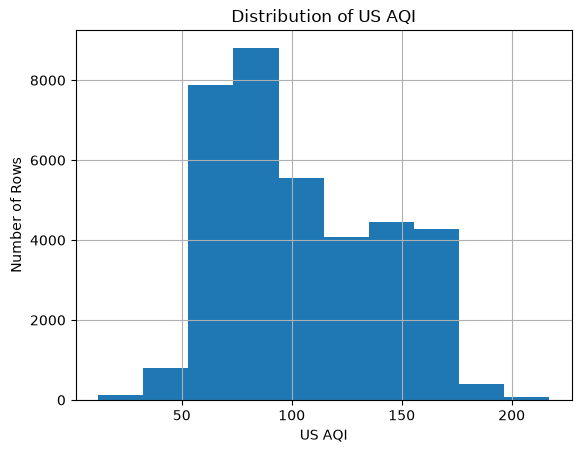

In [16]:
df["us_aqi"].hist()
plt.xlabel("US AQI")
plt.ylabel("Number of Rows")
plt.title("Distribution of US AQI")
plt.show()

### 3.2 AQI by hour of day

In [17]:
df["hour"] = df["time"].dt.hour

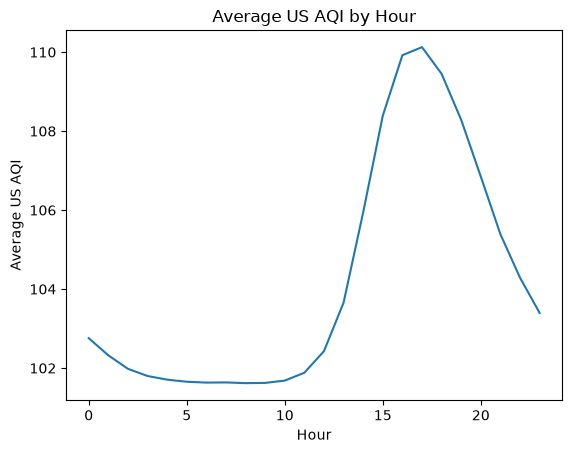

In [18]:
df.groupby("hour")["us_aqi"].mean().plot()

plt.xlabel("Hour")
plt.ylabel("Average US AQI")
plt.title("Average US AQI by Hour")
plt.show()

### 3.3 AQI by month (seasonal pattern)

In [19]:
df["month"] = df["time"].dt.month

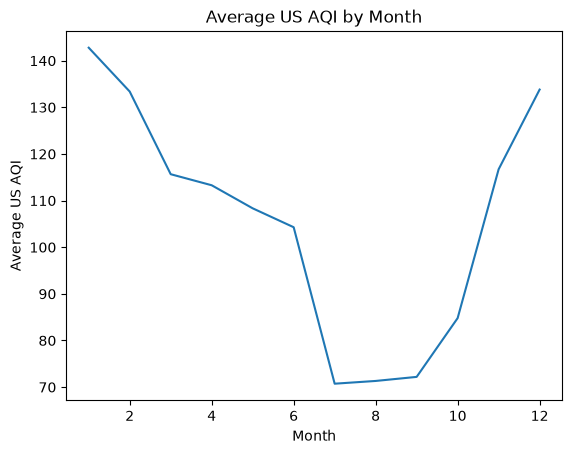

In [20]:
df.groupby("month")["us_aqi"].mean().plot()

plt.xlabel("Month")
plt.ylabel("Average US AQI")
plt.title("Average US AQI by Month")
plt.show()

### 3.4 Number of hours in each AQI category

In [21]:
pd.cut(df["us_aqi"], bins =[0, 50, 100, 150, 200, 300, 500]).value_counts()

us_aqi
(50, 100]     19515
(100, 150]     9866
(150, 200]     6384
(0, 50]         617
(200, 300]       45
(300, 500]        0
Name: count, dtype: int64

### 3.5 Correlation with `us_aqi`

In [22]:
df.corr()['us_aqi'].sort_values()

dew_point_2m           -0.539782
apparent_temperature   -0.495870
temperature_2m         -0.420693
cloud_cover            -0.370203
weather_code           -0.326138
month                  -0.279714
relative_humidity_2m   -0.252539
rain                   -0.196388
precipitation          -0.196388
day_of_week            -0.026582
is_weekend             -0.021520
hour                    0.053771
wind_direction_10m      0.064849
wind_gusts_10m          0.090207
wind_speed_10m          0.102072
time                    0.172280
nitrogen_dioxide        0.178548
ozone                   0.322454
carbon_monoxide         0.392728
pressure_msl            0.404573
sulphur_dioxide         0.574293
pm10                    0.719540
pm2_5                   0.730693
us_aqi                  1.000000
Name: us_aqi, dtype: float64

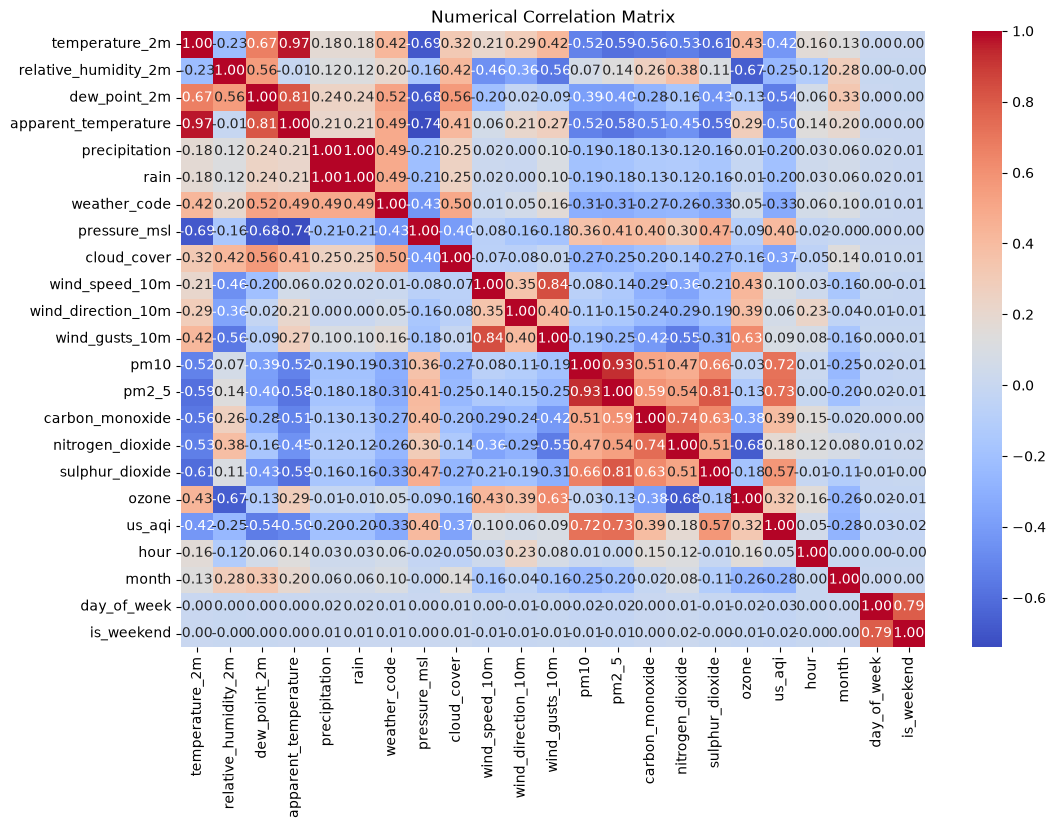

In [23]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Correlation Matrix")
plt.show()

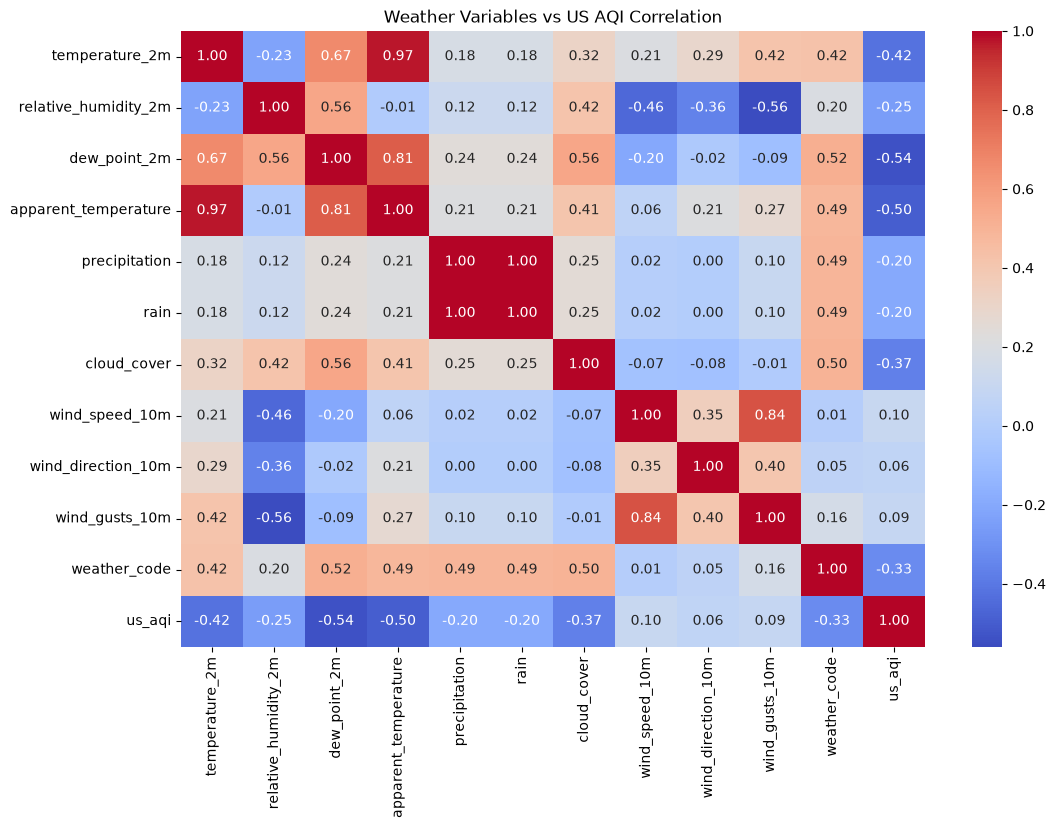

In [25]:
weather_cols = [
    "temperature_2m",
    "relative_humidity_2m",
    "dew_point_2m",
    "apparent_temperature",
    "precipitation",
    "rain",
    "cloud_cover",
    "wind_speed_10m",
    "wind_direction_10m",
    "wind_gusts_10m",
    "weather_code",
    "us_aqi"
]

weather_corr = df[weather_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(weather_corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Weather Variables vs US AQI Correlation")
plt.show()

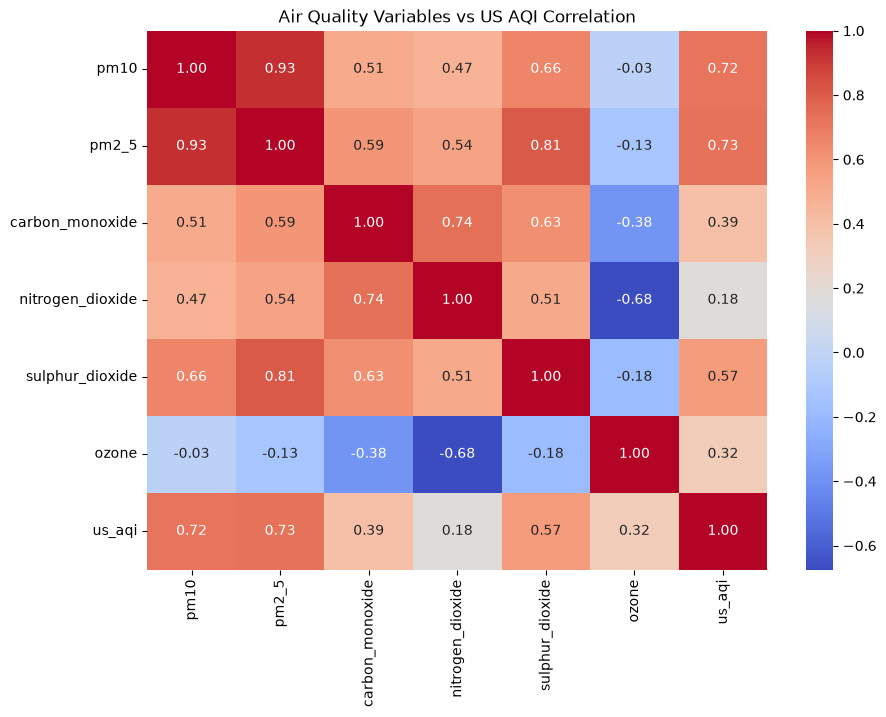

In [27]:
air_quality_cols = [
    "pm10",
    "pm2_5",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone",
    "us_aqi"
]

air_quality_corr = df[air_quality_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(air_quality_corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Air Quality Variables vs US AQI Correlation")
plt.show()

### 3.6 Correlation heatmap (all features)

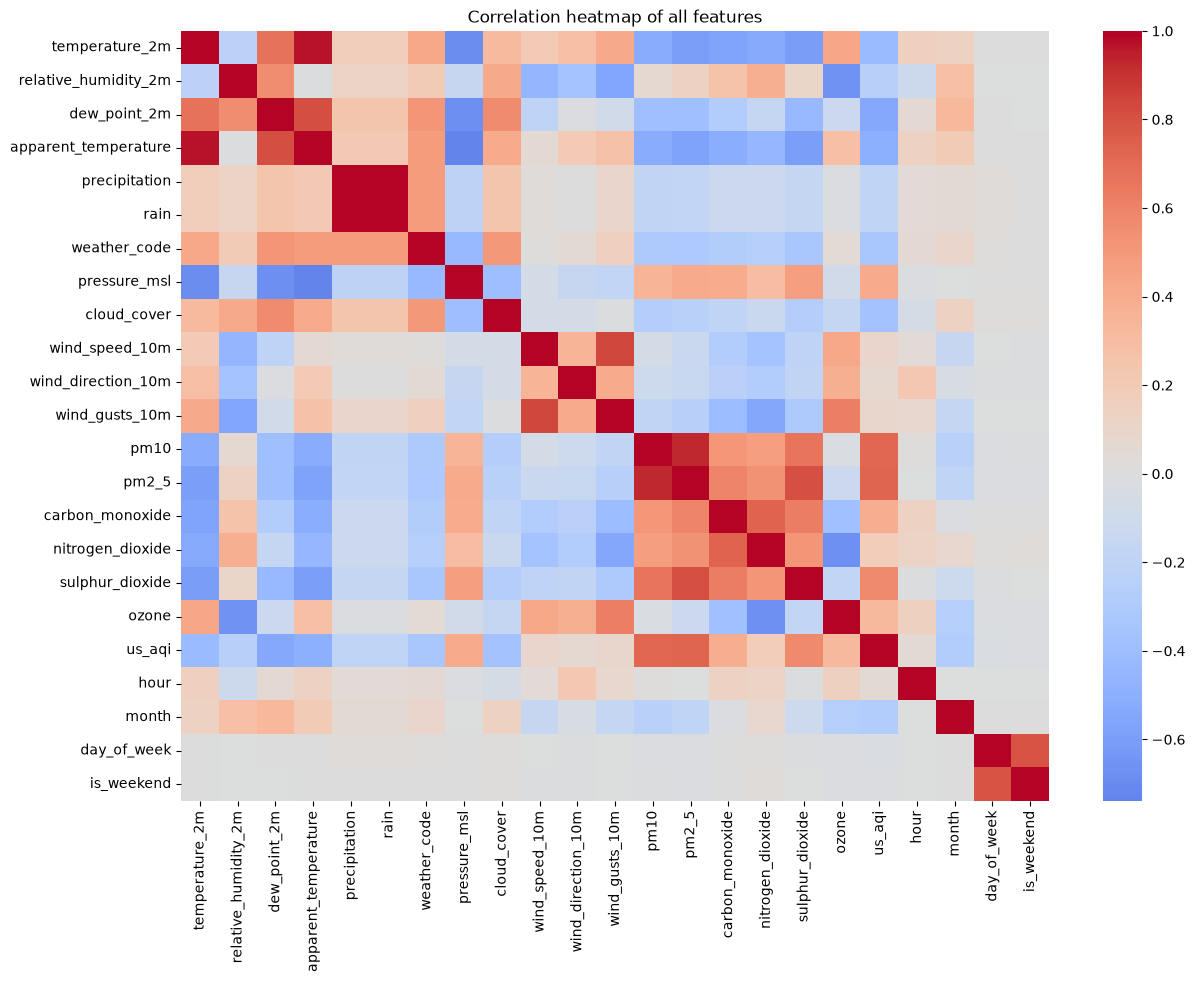

In [28]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.drop(columns="time").corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap of all features")
plt.show()

In [29]:
import numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# EPA breakpoints: (C_low, C_high, I_low, I_high)
BP_PM25_2024 = [(0,9.0,0,50),(9.1,35.4,51,100),(35.5,55.4,101,150),(55.5,125.4,151,200),(125.5,225.4,201,300),(225.5,325.4,301,500)]
BP_PM25_OLD  = [(0,12.0,0,50),(12.1,35.4,51,100),(35.5,55.4,101,150),(55.5,150.4,151,200),(150.5,250.4,201,300),(250.5,500.4,301,500)]
BP_PM10      = [(0,54,0,50),(55,154,51,100),(155,254,101,150),(255,354,151,200),(355,424,201,300),(425,604,301,500)]

def sub_aqi(conc, bps, trunc):
    c = np.floor(conc / trunc) * trunc            # EPA truncation
    out = np.full(len(c), np.nan)
    for cl, ch, il, ih in bps:
        m = (c >= cl) & (c <= ch)
        out[m] = (ih - il) / (ch - cl) * (c[m] - cl) + il
    return np.round(out)

pm25_24h = df["pm2_5"].rolling(24, min_periods=24).mean()
pm10_24h = df["pm10"].rolling(24, min_periods=24).mean()

results = {}
for name, bp in [("PM2.5 breakpoints pre-2024", BP_PM25_OLD), ("PM2.5 breakpoints 2024", BP_PM25_2024)]:
    rebuilt = np.fmax(sub_aqi(pm25_24h.values, bp, 0.1), sub_aqi(pm10_24h.values, BP_PM10, 1))
    ok = ~np.isnan(rebuilt)
    err = np.abs(rebuilt[ok] - df["us_aqi"].values[ok])
    results[name] = (rebuilt, np.corrcoef(rebuilt[ok], df["us_aqi"].values[ok])[0,1], err.mean(), (err<=5).mean())
    print(f"{name}: r={results[name][1]:.3f}  MAE={err.mean():.2f}  within +-5: {(err<=5).mean():.0%}")

best = max(results, key=lambda k: results[k][1])
rebuilt = results[best][0]
plt.figure(figsize=(6,6))
plt.scatter(df["us_aqi"], rebuilt, s=3, alpha=0.3)
plt.plot([0,300],[0,300],"r--")
plt.xlabel("Reported US AQI (Open-Meteo)"); plt.ylabel("AQI rebuilt from pollutants (EPA formula)")
plt.title(f"Pollutants rebuild the AQI ({best}, r={results[best][1]:.3f})")
plt.savefig("eda37.png", dpi=100)

PM2.5 breakpoints pre-2024: r=0.955  MAE=5.03  within +-5: 85%
PM2.5 breakpoints 2024: r=0.955  MAE=3.35  within +-5: 92%


## 4. Train / test split (time-based)
Train on the past, test on the future, so the model never sees future data.
- **Train:** Oct 2022 to Sep 2025 - 3 years
- **Test:** Oct 2025 to Sep 2026 - 1 year

In [30]:
# Training data: October 2022 – September 2025
train_df = df[
    (df['time'] >= '2022-10-01') &
    (df['time'] < '2025-10-01')
].copy()

# Testing data: October 2025 – September 2026
test_df = df[
    (df['time'] >= '2025-10-01') &
    (df['time'] < '2026-10-01')
].copy()

In [31]:
# Mean US AQI for each October–September year (train and test)
periods = [
    ("Oct 2022 to Sep 2023", "2022-10-01", "2023-10-01", "Train"),
    ("Oct 2023 to Sep 2024", "2023-10-01", "2024-10-01", "Train"),
    ("Oct 2024 to Sep 2025", "2024-10-01", "2025-10-01", "Train"),
    ("Oct 2025 to Sep 2026", "2025-10-01", "2026-10-01", "Test"),
]

rows = []
for name, start, end, role in periods:
    mask = (df["time"] >= start) & (df["time"] < end)
    rows.append({
        "Period": name,
        "Role": role,
        "Mean AQI": round(df.loc[mask, "us_aqi"].mean(), 1),
        "Hours": int(mask.sum()),
    })

aqi_by_year = pd.DataFrame(rows)
print(aqi_by_year.to_string(index=False))
aqi_by_year.to_csv("mean_aqi_by_year.csv", index=False)
aqi_by_year

              Period  Role  Mean AQI  Hours
Oct 2022 to Sep 2023 Train     100.2   8760
Oct 2023 to Sep 2024 Train      88.2   8784
Oct 2024 to Sep 2025 Train     118.3   8760
Oct 2025 to Sep 2026  Test     115.3   8760


,Period,Role,Mean AQI,Hours
0,Oct 2022 to Sep 2023,Train,100.2,8760
1,Oct 2023 to Sep 2024,Train,88.2,8784
2,Oct 2024 to Sep 2025,Train,118.3,8760
3,Oct 2025 to Sep 2026,Test,115.3,8760


In [33]:
train_df.tail()

,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,weather_code,pressure_msl,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi,hour,month,day_of_week,is_weekend
27662,2025-09-30 19:00:00,20.4,96,19.8,23.8,0.0,0.0,1,1007.6,44,3.0,163,10.1,33.4,33.2,2102.0,24.0,7.0,67.0,81.0,19,9,1,0
27663,2025-09-30 20:00:00,19.5,100,19.5,22.6,0.0,0.0,3,1009.0,100,3.6,162,10.8,34.6,34.3,2510.0,29.0,8.3,58.0,80.0,20,9,1,0
27664,2025-09-30 21:00:00,18.9,100,18.9,21.9,0.0,0.0,3,1009.3,100,3.0,163,10.8,36.8,36.4,2527.0,32.0,9.1,52.0,80.0,21,9,1,0
27665,2025-09-30 22:00:00,18.8,100,18.8,21.5,0.0,0.0,3,1009.5,100,3.9,164,11.5,40.0,39.8,2318.0,33.8,9.5,47.0,79.0,22,9,1,0
27666,2025-09-30 23:00:00,18.5,100,18.5,21.3,0.0,0.0,3,1009.3,100,2.4,171,12.2,40.7,40.5,2045.0,34.4,9.7,44.0,80.0,23,9,1,0


In [34]:
test_df.tail()

,time,temperature_2m,relative_humidity_2m,dew_point_2m,apparent_temperature,precipitation,rain,weather_code,pressure_msl,cloud_cover,wind_speed_10m,wind_direction_10m,wind_gusts_10m,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi,hour,month,day_of_week,is_weekend
36422,2026-09-30 19:00:00,20.8,95,20.0,24.2,0.0,0.0,0,1013.3,12,3.4,328,7.2,35.7,34.2,1729.0,14.5,7.3,96.0,76.0,19,9,2,0
36423,2026-09-30 20:00:00,20.6,96,20.0,24.1,0.0,0.0,0,1014.2,13,2.6,335,6.8,36.9,35.4,2102.0,16.1,8.3,95.0,77.0,20,9,2,0
36424,2026-09-30 21:00:00,20.7,95,20.0,24.4,0.0,0.0,0,1014.7,13,1.2,51,5.0,35.0,33.5,2419.0,15.6,8.8,97.0,78.0,21,9,2,0
36425,2026-09-30 22:00:00,20.4,97,19.9,24.0,0.0,0.0,0,1014.7,7,1.2,51,3.6,36.9,35.4,2673.0,14.0,9.0,100.0,78.0,22,9,2,0
36426,2026-09-30 23:00:00,20.1,98,19.9,23.5,0.0,0.0,0,1014.1,5,3.1,13,3.2,36.4,34.9,2710.0,12.5,9.1,100.0,79.0,23,9,2,0


## 5. Feature engineering: cyclic encoding of hour and month
Hour 23 and hour 0 are neighbours in real life, and so are month 12 and month 1. Sine and cosine put them on a circle so the model sees that. Both are needed because sine alone repeats (hour 0 and hour 12 both give 0).

In [35]:
# Apply cyclic encoding to training data
train_df['hour_sin'] = np.sin(2 * np.pi * train_df['hour'] / 24)
train_df['hour_cos'] = np.cos(2 * np.pi * train_df['hour'] / 24)

train_df['month_sin'] = np.sin(2 * np.pi * train_df['month'] / 12)
train_df['month_cos'] = np.cos(2 * np.pi * train_df['month'] / 12)


# Apply cyclic encoding to testing data
test_df['hour_sin'] = np.sin(2 * np.pi * test_df['hour'] / 24)
test_df['hour_cos'] = np.cos(2 * np.pi * test_df['hour'] / 24)

test_df['month_sin'] = np.sin(2 * np.pi * test_df['month'] / 12)
test_df['month_cos'] = np.cos(2 * np.pi * test_df['month'] / 12)

In [36]:
print("Training Data:")
print(train_df[['hour', 'month', 'hour_sin', 'hour_cos',
                'month_sin', 'month_cos']].head())

print("\nTesting Data:")
print(test_df[['hour', 'month', 'hour_sin', 'hour_cos',
               'month_sin', 'month_cos']].head())

Training Data:
      hour  month  hour_sin  hour_cos  month_sin  month_cos
1363     0     10  0.000000  1.000000  -0.866025        0.5
1364     1     10  0.258819  0.965926  -0.866025        0.5
1365     2     10  0.500000  0.866025  -0.866025        0.5
1366     3     10  0.707107  0.707107  -0.866025        0.5
1367     4     10  0.866025  0.500000  -0.866025        0.5

Testing Data:
       hour  month  hour_sin  hour_cos  month_sin  month_cos
27667     0     10  0.000000  1.000000  -0.866025        0.5
27668     1     10  0.258819  0.965926  -0.866025        0.5
27669     2     10  0.500000  0.866025  -0.866025        0.5
27670     3     10  0.707107  0.707107  -0.866025        0.5
27671     4     10  0.866025  0.500000  -0.866025        0.5


## 6. Feature selection
Weather and time features only. PM2.5 and PM10 are left out on purpose because US AQI is calculated from them, which would leak the answer into the inputs.

The sin/cos columns replace the raw `hour` and `month`.

In [37]:
features = ["temperature_2m", "dew_point_2m", "cloud_cover", "weather_code",
            "precipitation", "hour_sin", "hour_cos", "month_sin", "month_cos"]
target = "us_aqi"

df_weather_train = train_df[["time"] + features + [target]]
df_weather_test  = test_df[["time"] + features + [target]]

df_weather_train.columns

Index(['time', 'temperature_2m', 'dew_point_2m', 'cloud_cover', 'weather_code',
       'precipitation', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
       'us_aqi'],
      dtype='str')

In [38]:
df_weather_train.to_csv("kathmandu_weather_train.csv", index = False)
df_weather_test.to_csv("kathmandu_weather_test.csv", index = False)

## 7. Modeling: Random Forest Regressor
Inputs (`X`) are the selected features and the output (`y`) is `us_aqi`.

In [39]:
X_train, y_train = train_df[features], train_df[target]
X_test,  y_test  = test_df[features],  test_df[target]

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (26304, 9)  Test: (8760, 9)


In [40]:
model = RandomForestRegressor(n_estimators=200, random_state=12, n_jobs=-1)
model.fit(X_train, y_train)

pred = model.predict(X_test)

## 8. Evaluation

### 8.1 Regression metrics
- **MAE:** average error in AQI points
- **RMSE:** like MAE but penalises big misses more
- **R²:** share of AQI variation the model explains (1.0 is perfect)

In [41]:
base_mae  = mean_absolute_error(y_test, pred)
base_rmse = np.sqrt(mean_squared_error(y_test, pred))
base_r2   = r2_score(y_test, pred)

print(f"MAE : {base_mae:.2f}")
print(f"RMSE: {base_rmse:.2f}")
print(f"R2  : {base_r2:.3f}")

MAE : 21.43
RMSE: 27.53
R2  : 0.467


# Hyperparameter Tuning

In [42]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, 30, None],
    "min_samples_leaf": [1, 5, 10],
    "max_features": ["sqrt", 0.5, 1.0]
}

tscv = TimeSeriesSplit(n_splits=3)

search = RandomizedSearchCV(
    RandomForestRegressor(random_state=12, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    random_state=12,
)

search.fit(X_train, y_train)

print("Best settings:", search.best_params_)
print(f"Best CV MAE: {-search.best_score_:.2f}")

best_model = search.best_estimator_

Best settings: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 10}
Best CV MAE: 25.62


In [43]:
results = pd.DataFrame(search.cv_results_)
results = results[["param_n_estimators", "param_max_depth", "param_min_samples_leaf",
                   "param_max_features", "mean_test_score"]]
results["cv_mae"] = -results["mean_test_score"]
results = results.sort_values("cv_mae").drop(columns="mean_test_score")
results.to_csv("rf_tuning_results.csv", index=False)
results.head(10)

,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,cv_mae
10,200,10,10,sqrt,25.616207
7,100,30,10,sqrt,25.730197
13,300,10,10,0.5,25.769143
5,300,10,5,0.5,25.792874
12,200,20,5,sqrt,25.874229
3,300,None,10,0.5,25.881637
14,200,None,10,0.5,25.885106
11,200,20,5,0.5,26.009603
4,100,20,5,0.5,26.014300
8,300,10,10,1.0,26.101806


In [44]:
tuned_pred = best_model.predict(X_test)

comparison = pd.DataFrame({
    "Model": ["Random Forest (baseline)", "Random Forest (tuned)"],
    "MAE":  [base_mae,  mean_absolute_error(y_test, tuned_pred)],
    "RMSE": [base_rmse, np.sqrt(mean_squared_error(y_test, tuned_pred))],
    "R2":   [base_r2,   r2_score(y_test, tuned_pred)],
}).round(3)
comparison

,Model,MAE,RMSE,R2
0,Random Forest (baseline),21.428,27.527,0.467
1,Random Forest (tuned),20.444,25.717,0.535


In [50]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, TimeSeriesSplit

# 1) Alpha grid: 5-fold validation MAE on the TRAINING data only
alphas = [0.01, 0.1, 1, 10, 100, 1000]
cv = TimeSeriesSplit(n_splits=5)   # time-ordered folds, same idea as the tuning cell

alpha_cv = {}
for a in alphas:
    pipe = make_pipeline(StandardScaler(), Ridge(alpha=a))
    scores = cross_val_score(pipe, X_train, y_train, cv=cv,
                             scoring="neg_mean_absolute_error")
    alpha_cv[a] = -scores.mean()

alpha_table = pd.DataFrame({
    "Alpha": alphas,
    "Validation MAE (average of 5 folds)": [round(alpha_cv[a], 3) for a in alphas],
})
print(alpha_table.to_string(index=False))

best_alpha = min(alpha_cv, key=alpha_cv.get)
print("Best alpha:", best_alpha)

# 2) Refit on the full training set and score on the test set
lin   = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
ridge = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)).fit(X_train, y_train)

def metrics(name, yhat):
    return {"Model": name,
            "MAE":  mean_absolute_error(y_test, yhat),
            "RMSE": np.sqrt(mean_squared_error(y_test, yhat)),
            "R2":   r2_score(y_test, yhat)}

linear_table = pd.DataFrame([
    metrics("Linear Regression", lin.predict(X_test)),
    metrics(f"Ridge (best alpha = {best_alpha})", ridge.predict(X_test)),
]).round(3)

# 3) Full comparison: Random Forest rows from the earlier cell + linear rows
full_comparison = pd.concat([comparison, linear_table], ignore_index=True)
full_comparison

  Alpha  Validation MAE (average of 5 folds)
   0.01                               29.417
   0.10                               29.417
   1.00                               29.412
  10.00                               29.362
 100.00                               28.914
1000.00                               26.823
Best alpha: 1000


,Model,MAE,RMSE,R2
0,Random Forest (baseline),21.428,27.527,0.467
1,Random Forest (tuned),20.444,25.717,0.535
2,Linear Regression,22.738,28.199,0.441
3,Ridge (best alpha = 1000),23.142,28.748,0.419


### 8.2 Confusion matrix (AQI categories)
A confusion matrix needs classes, so both the real and the predicted AQI are grouped into AQI categories, then compared.

In [45]:
bins   = [-1, 50, 100, 150, 200, 500]
labels = ["Good", "Moderate", "Unhealthy (sensitive)", "Unhealthy", "Very Unhealthy+"]

y_test_cat = pd.cut(y_test, bins=bins, labels=labels)
pred_cat   = pd.cut(pred,   bins=bins, labels=labels)

cm = confusion_matrix(y_test_cat, pred_cat, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues", xticks_rotation=30)
plt.title("AQI category confusion matrix")
plt.show()

C:\Users\asus\AppData\Local\Temp\ipykernel_38828\122157552.py:10: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 9. Save the model (deployment step)
Save the trained model to a file, load it back, and predict with the loaded copy to prove it works.

In [46]:
joblib.dump(best_model, "rf_aqi_model.pkl")



['rf_aqi_model.pkl']

In [47]:
loaded_model = joblib.load("rf_aqi_model.pkl")
print(loaded_model.predict(X_test.sample(10)))

[ 70.40744897 107.01554318  71.32428367 126.64108979  71.69567533
 106.28611549  67.75803597  81.58425492 132.98431286  74.89545636]


In [48]:
print(loaded_model.predict(X_test.iloc[[100]]), y_test.iloc[[100]])

[83.8221987] 27767    65.0
Name: us_aqi, dtype: float64


In [49]:
errors = (pred - y_test).abs()
print(errors.describe())          # typical error, worst error, spread

plt.scatter(y_test, pred, s=3, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual AQI"); plt.ylabel("Predicted AQI")
plt.title("Actual vs predicted AQI")
plt.show()

count    8760.000000
mean       21.427654
std        17.281245
min         0.000000
25%         7.975937
50%        16.997500
75%        31.068759
max       117.755000
Name: us_aqi, dtype: float64


C:\Users\asus\AppData\Local\Temp\ipykernel_38828\80072704.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
